
[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9466 - loss: 0.1744 - val_accuracy: 0.9877 - val_loss: 0.0453
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9802 - loss: 0.0647 - val_accuracy: 0.9880 - val_loss: 0.0422
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9849 - loss: 0.0460 - val_accuracy: 0.9895 - val_loss: 0.0373
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9886 - loss: 0.0364 - val_accuracy: 0.9910 - val_loss: 0.0348
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.9911 - loss: 0.0287 - val_accuracy: 0.9898 - val_loss: 0.0370

Test Accuracy: 99.04%


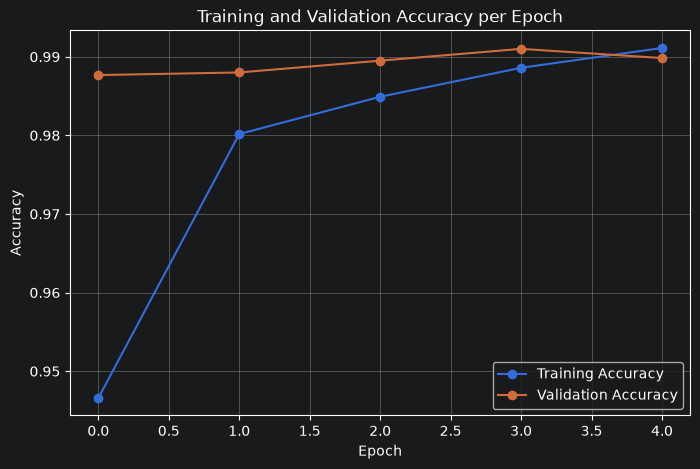

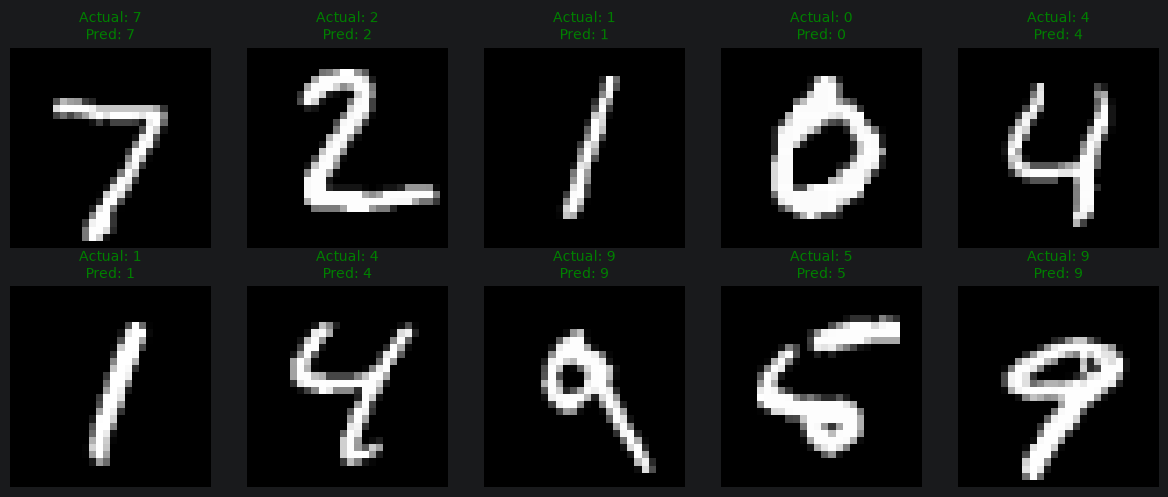

In [1]:
# Write a program in a Jupyter notebook that trains a Convolutional Neural Network (CNN) using
# the MNIST dataset, evaluates its accuracy, displays training and validation accuracy graphs,
# and shows 10 handwritten digits with their actual and predicted values.
# Step 1: Import libraries
!pip install tensorflow numpy matplotlib
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

# Step 2: Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

# Step 3: Normalize images to range [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Step 4: Reshape images for CNN (adding channel dimension: 28x28x1)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Step 5: Build an 8-Layer CNN model
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),  # Layer 1
    layers.MaxPooling2D((2, 2)),                  # Layer 2

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),  # Layer 3
    layers.MaxPooling2D((2, 2)),                  # Layer 4

    # Classifier Head
    layers.Flatten(),                             # Layer 5
    layers.Dense(128, activation='relu'),         # Layer 6
    layers.Dropout(0.3),                          # Layer 7
    layers.Dense(10, activation='softmax')        # Layer 8 (Output)
])

# Step 6: Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 7: Display CNN architecture summary
model.summary()

# Step 8: Train CNN and save history for graphs
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# Step 9: Evaluate CNN on test data
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")

# Step 10: Plot Training and Validation Accuracy Graphs
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Step 11: Display 10 Test Digits with Actual and Predicted Values
predictions = model.predict(X_test[:10], verbose=0)
predicted_digits = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    actual = y_test[i]
    pred = predicted_digits[i]
    color = 'green' if pred == actual else 'red'
    plt.title(f"Actual: {actual}\nPred: {pred}", color=color, fontsize=10)
    plt.axis('off')


plt.tight_layout()
plt.show()